# Solución numérica del flujo de Couette 1D Estado no estacionario 

Resolvemos la ecuación de difusión viscosa:

$$\frac{\partial u}{\partial t} = \nu \frac{\partial^2 u}{\partial y^2}$$

**Condiciones de contorno (Dirichlet):**
- $u(y=0, t) = 0$ → placa inferior fija
- $u(y=1, t) = 1$ → placa superior móvil

**Condición inicial:**
- $u(y, 0) = 0$ → fluido en reposo

**Solución analítica estacionaria:**
- $u(y) = y$ → perfil lineal

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

## 1. Parámetros y dominio

In [3]:
# Parámetros del dominio
ny = 51               # número de puntos en y
nt = 5000000          # número de pasos de tiempo
nu = 0.1              # viscosidad cinemática
tau = 1         # constante de tiempo del arranque progresivo de la placa

dy = 1.0 / (ny - 1)   # espaciado en y
dt = 0.000001           # paso de tiempo

# Verificación de estabilidad (número de Fourier < 0.5)
F = nu * dt / dy**2

# Dominio espacial
y = np.linspace(0, 1, ny)

# Velocidad de la placa superior con arranque progresivo: 1 - e^(-t/tau)
def u_plate(t):
    return 1.0 - np.exp(-t / tau)


## 2. Condiciones iniciales y de contorno

In [5]:
# Condición inicial: fluido en reposo
u = np.zeros(ny)

# Condiciones de contorno (se imponen aquí y en cada paso de tiempo)
u[0]  = 0.0          # placa inferior fija
u[-1] = u_plate(0.0) # placa superior con arranque progresivo (= 0 en t=0)

# Array para guardar el historial completo
uf = np.zeros((nt, ny))
uf[0] = u.copy()


## 3. Bucle temporal (esquema explícito FTCS)

In [8]:
for n in range(1, nt):
    un = u.copy()  # copia del paso anterior (¡imprescindible!)

    # Diferencias finitas centradas para ∂²u/∂y² (nodos interiores)
    u[1:-1] = un[1:-1] + nu * dt / dy**2 * (un[2:] - 2*un[1:-1] + un[:-2])

    # Reimposición de condiciones de contorno en cada paso
    u[0]  = 0.0
    u[-1] = u_plate(n * dt)   # placa superior con arranque progresivo

    uf[n] = u.copy()


## 4. Visualización: evolución temporal del perfil

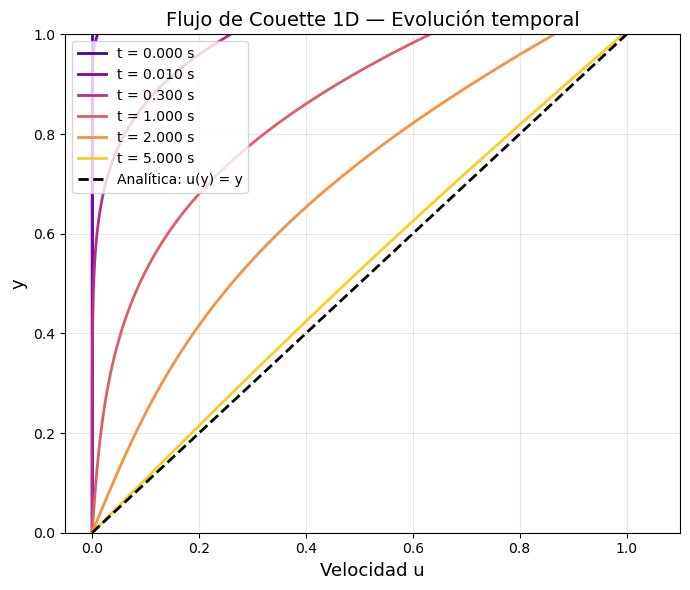

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

# Instantes a visualizar
tiempos = [0, 10000, 300000, 1000000, 2000000,nt - 1]
colores = cm.plasma(np.linspace(0.1, 0.9, len(tiempos)))

for i, n in enumerate(tiempos):
    t_actual = n * dt
    ax.plot(uf[n], y, color=colores[i], linewidth=2,
            label=f"t = {t_actual:.3f} s")

# Solución analítica estacionaria
ax.plot(y, y, 'k--', linewidth=2, label="Analítica: u(y) = y")

ax.set_xlabel("Velocidad u", fontsize=13)
ax.set_ylabel("y", fontsize=13)
ax.set_title("Flujo de Couette 1D — Evolución temporal", fontsize=14)
ax.legend(loc="upper left", fontsize=10)
ax.set_xlim(-0.05, 1.1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()